# 5. Leave-One-Country-Out (LOCO) Fine-Tuning

Transfer learning from Fetal DB pre-trained weights onto the African dataset,
evaluated with **Leave-One-Country-Out Cross-Validation (LOCO-CV)**.

In each of the 4 folds:
- **Test set**: Fixed as Malawi (never touched during CV)
- **Validation set**: One of the other 4 countries (rotated each fold)
- **Train set**: The remaining 3 countries

Tested for 3 architectures: EfficientNet-B0, ConvNeXt-Tiny, EfficientFormerV2-S0.
Weights were trained on 3 classes only (`brain`, `femur`, `abdomen`).

**Note on CSV**: `Plane` column uses `"Fetal brain"` etc. - these are remapped to
`brain`, `femur`, `abdomen` before training.


In [ ]:
# Environment setup: make modelling/ the working directory.
# Works when launched from the repo root, from modelling/, from modelling/notebooks/,
# or on Kaggle/Colab (where the public repository is cloned first).
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/PaulOkwija/US_standard_plane_classification.git"

if Path("src").is_dir() and Path("configs").is_dir():
    pass                                   # already in modelling/
elif Path("../src").is_dir():
    os.chdir("..")                         # modelling/notebooks/
elif Path("modelling/src").is_dir():
    os.chdir("modelling")                  # repo root
else:
    repo_dir = Path("US_standard_plane_classification")
    if not repo_dir.exists():
        subprocess.run(["git", "clone", REPO_URL, str(repo_dir)], check=True)
    os.chdir(repo_dir / "modelling")

sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

In [ ]:
# -- Download datasets and pretrained weights -------------------------------
!bash scripts/download_data.sh
!bash scripts/download_weights.sh

In [ ]:
# Optional: Weights & Biases tracking. Provide WANDB_API_KEY as an environment
# variable (or a Kaggle secret named WANDB). Without it, pass tracker="none".
import os
if "WANDB_API_KEY" not in os.environ:
    try:
        from kaggle_secrets import UserSecretsClient
        os.environ["WANDB_API_KEY"] = UserSecretsClient().get_secret("WANDB")
    except Exception:
        print("WANDB_API_KEY not set; W&B logging will be unavailable.")

Loaded 450 rows | Columns: ['Patient_num', 'Plane', 'Train', 'Center', 'Filename', 'label', 'Filename_png']
Centers: ['Algeria', 'Egypt', 'Ghana', 'Malawi', 'Uganda']
Label distribution:
label
abdomen    125
femur      125
brain      125
other       75
Name: count, dtype: int64

375 images after filtering to 3 classes


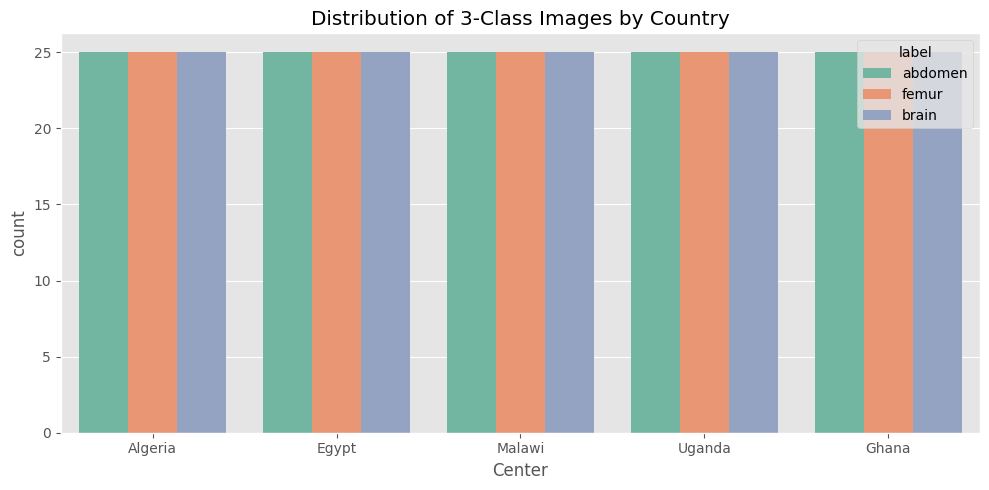

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path

plt.style.use('ggplot')

# CSV path lives in raw_data not data/african 
AFRICAN_CSV = "raw_data/African_planes_database.csv"
AFRICAN_DIR = "data/african"   # root where country/class/image folders live

#  Plane label remapping 
# CSV uses "Fetal brain", "Fetal femur", "Fetal abdomen"
# Our model was trained on "brain", "femur", "abdomen"
PLANE_REMAP = {
    "fetal brain"   : "brain",
    "fetal femur"   : "femur",
    "fetal abdomen" : "abdomen",
    "fetal thorax"  : "other",
}
CLASSES_3C = ["brain", "femur", "abdomen"]

if not os.path.exists(AFRICAN_CSV):
    print(f"[WARN] CSV not found at {AFRICAN_CSV}")
else:
    df_raw = pd.read_csv(AFRICAN_CSV)
    df_raw["Center"] = df_raw["Center"].str.strip()

    # Remap Plane
    df_raw["label"] = df_raw["Plane"].str.lower().str.strip().map(PLANE_REMAP)

    # Add .png extension to Filename
    df_raw["Filename_png"] = df_raw["Filename"].str.strip() + ".png"

    print(f"Loaded {len(df_raw)} rows | Columns: {df_raw.columns.tolist()}")
    print(f"Centers: {sorted(df_raw['Center'].unique().tolist())}")
    print(f"Label distribution:\n{df_raw['label'].value_counts()}")

    # Filter to 3 standard classes only
    df_3c = df_raw[df_raw["label"].isin(CLASSES_3C)].copy()
    print(f"\n{len(df_3c)} images after filtering to 3 classes")

    fig, ax = plt.subplots(figsize=(10, 5))
    sns.countplot(data=df_3c, x="Center", hue="label", ax=ax,
                  palette="Set2")
    ax.set_title("Distribution of 3-Class Images by Country")
    plt.tight_layout()
    plt.show()


## 1. Run LOCO-CV Transfer Learning

For each model, runs 4 folds (one per non-Malawi country as validation),
then evaluates the best model from each fold on the held-out Malawi test set.


In [ ]:
models_to_test = [
    {
        "name"   : "efficientnet_b0",
        "weights": "checkpoints/efficientnetb0_base_3c.pt"
    },
    {
        "name"   : "convnext_tiny",
        "weights": "checkpoints/covnext_base_3c.pt"   
    },
    {
        "name"   : "efficientformerv2_s0",
        "weights": "checkpoints/efficientformerV2_base_3c.pt"
    },
]


In [9]:
import torch
ckpt = torch.load("checkpoints/efficientnetb0_base_3c.pt", map_location="cpu")
print(type(ckpt))
print(ckpt.keys() if isinstance(ckpt, dict) else "bare state dict")
# If it has model_state_dict:
sd = ckpt.get("model_state_dict", ckpt)
# Find the classifier/head layer
head_keys = [k for k in sd.keys() if "classifier" in k or "head" in k or "fc" in k]
print("Head keys:", head_keys)
for k in head_keys:
    print(k, sd[k].shape)

<class 'dict'>
dict_keys(['model_state_dict', 'optimizer_state_dict', 'metrics', 'config'])
Head keys: ['conv_head.weight', 'classifier.weight', 'classifier.bias']
conv_head.weight torch.Size([1280, 320, 1, 1])
classifier.weight torch.Size([3, 1280])
classifier.bias torch.Size([3])


In [10]:
import yaml
with open("configs/base_config.yaml") as f:
    cfg = yaml.safe_load(f)
print("fine_tune_lr:", cfg["transfer_learning"]["fine_tune_lr"])
print("fine_tune_epochs:", cfg["transfer_learning"]["fine_tune_epochs"])
print("fine_tune_layers:", cfg["transfer_learning"]["fine_tune_layers"])

fine_tune_lr: 5e-05
fine_tune_epochs: 20
fine_tune_layers: 4


In [11]:
for model in models_to_test:
    m_name    = model["name"]
    m_weights = model["weights"]

    if not os.path.exists(m_weights):
        print(f"[SKIP] {m_name} - weights not found at {m_weights}")
        continue

    if not os.path.exists(AFRICAN_CSV):
        print(f"[SKIP] CSV not found at {AFRICAN_CSV}")
        continue

    print("=" * 60)
    print(f"Running LOCO-CV for: {m_name}")
    print("=" * 60)

    !python scripts/run_loco_cv.py \
        --model      {m_name} \
        --checkpoint {m_weights} \
        --african_csv {AFRICAN_CSV} \
        --african_dir {AFRICAN_DIR} \
        --tracker wandb

    print()


Running LOCO-CV for: efficientnet_b0
10:04:45 | INFO     | run_loco_cv | Running LOCO-CV for model: efficientnet_b0
10:04:45 | INFO     | run_loco_cv | Pretrained weights     : checkpoints/efficientnetb0_base_3c.pt
10:04:45 | INFO     | src.data.loco_cv | After class filter: 375 images  |  classes: ['brain', 'femur', 'abdomen']
10:04:45 | INFO     | src.data.loco_cv | LOCO-CV pool : 300 images | 4 countries
10:04:45 | INFO     | src.data.loco_cv | Malawi test  : 75 images
10:04:45 | INFO     | src.data.dataset | Found 450 images in index under data/african
10:04:45 | INFO     | src.data.loco_cv | ===== Fold 0 | Val country: Algeria =====
10:04:45 | INFO     | src.data.loco_cv |   Train: 225 | Val: 75
10:04:45 | INFO     | src.data.dataset | Found 450 images in index under data/african
10:04:45 | INFO     | src.data.dataset | Found 450 images in index under data/african
10:04:46 | INFO     | src.data.loco_cv | Missing keys  : []
10:04:46 | INFO     | src.data.loco_cv | Unexpected keys: 

## 2. Compare Results


In [12]:
results = {}

for model in models_to_test:
    m_name   = model["name"]
    res_path = f"results/loco_cv/{m_name}_loco_results.json"

    if os.path.exists(res_path):
        with open(res_path) as f:
            results[m_name] = json.load(f)
        print(f"Loaded results for {m_name}")
    else:
        print(f"[MISSING] {res_path}")

if not results:
    print("No results found - run the training cells above first.")


Loaded results for efficientnet_b0
Loaded results for convnext_tiny
Loaded results for efficientformerv2_s0


Malawi Held-out Test Set Performance (mean across folds):
                      pr_auc     auc      f1  accuracy
efficientnet_b0       0.9987  0.9993  0.9697    0.9700
convnext_tiny         0.9938  0.9964  0.9795    0.9800
efficientformerv2_s0  0.9983  0.9991  0.9733    0.9733


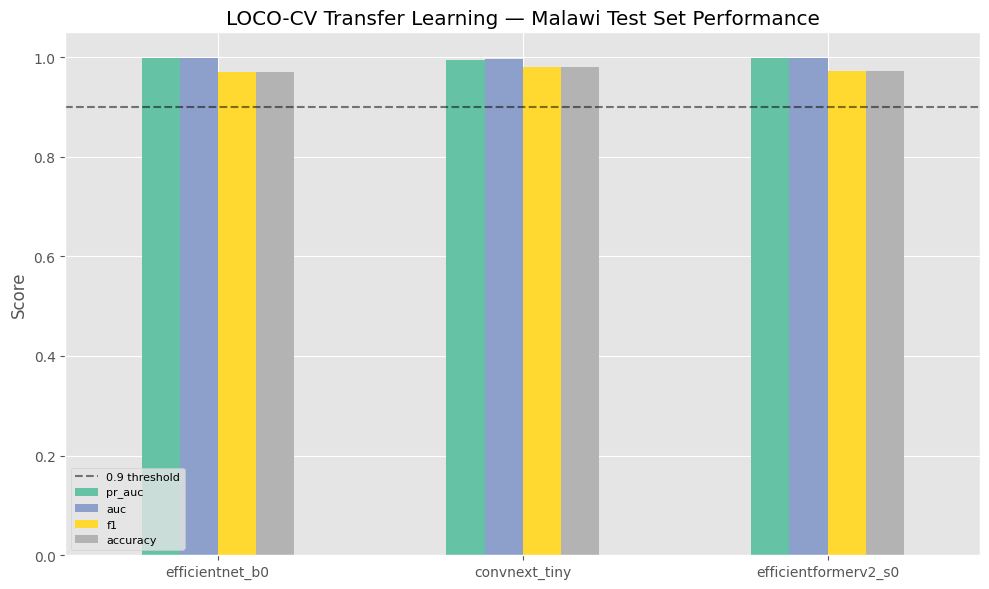

In [13]:
if results:
    # -- Mean test metrics on Malawi ---------------------------------------
    df_test = pd.DataFrame(
        {k: v["mean_test_metrics"] for k, v in results.items()}
    ).T

    # Keep numeric metric columns - note our metrics use 'f1' not 'f1_macro'
    metric_cols = [c for c in ["pr_auc", "auc", "f1", "accuracy"]
                   if c in df_test.columns]
    df_test = df_test[metric_cols]

    print("Malawi Held-out Test Set Performance (mean across folds):")
    print(df_test.round(4).to_string())

    fig, ax = plt.subplots(figsize=(10, 6))
    df_test.plot(kind="bar", ax=ax, colormap="Set2")
    ax.set_ylim(0, 1.05)
    ax.set_title("LOCO-CV Transfer Learning - Malawi Test Set Performance")
    ax.set_ylabel("Score")
    ax.axhline(0.9, color="black", linestyle="--", alpha=0.5, label="0.9 threshold")
    ax.legend(fontsize=8)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig("docs/loco_test_comparison.png", dpi=150)
    plt.show()


CV Fold Results:
               Model Val Country   PR-AUC       F1  Accuracy
     efficientnet_b0     Algeria 1.000000 0.986661  0.986667
     efficientnet_b0       Egypt 1.000000 0.946323  0.946667
     efficientnet_b0       Ghana 0.998500 0.973574  0.973333
     efficientnet_b0      Uganda 1.000000 0.973039  0.973333
       convnext_tiny     Algeria 1.000000 1.000000  1.000000
       convnext_tiny       Egypt 1.000000 1.000000  1.000000
       convnext_tiny       Ghana 1.000000 1.000000  1.000000
       convnext_tiny      Uganda 1.000000 1.000000  1.000000
efficientformerv2_s0     Algeria 1.000000 1.000000  1.000000
efficientformerv2_s0       Egypt 0.997966 0.973333  0.973333
efficientformerv2_s0       Ghana 1.000000 0.986661  0.986667
efficientformerv2_s0      Uganda 1.000000 1.000000  1.000000


/tmp/ipykernel_24/3035090416.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_cv,   x="Model", y=metric, ax=ax, palette="Set2")
/tmp/ipykernel_24/3035090416.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_cv,   x="Model", y=metric, ax=ax, palette="Set2")
/tmp/ipykernel_24/3035090416.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_cv,   x="Model", y=metric, ax=ax, palette="Set2")


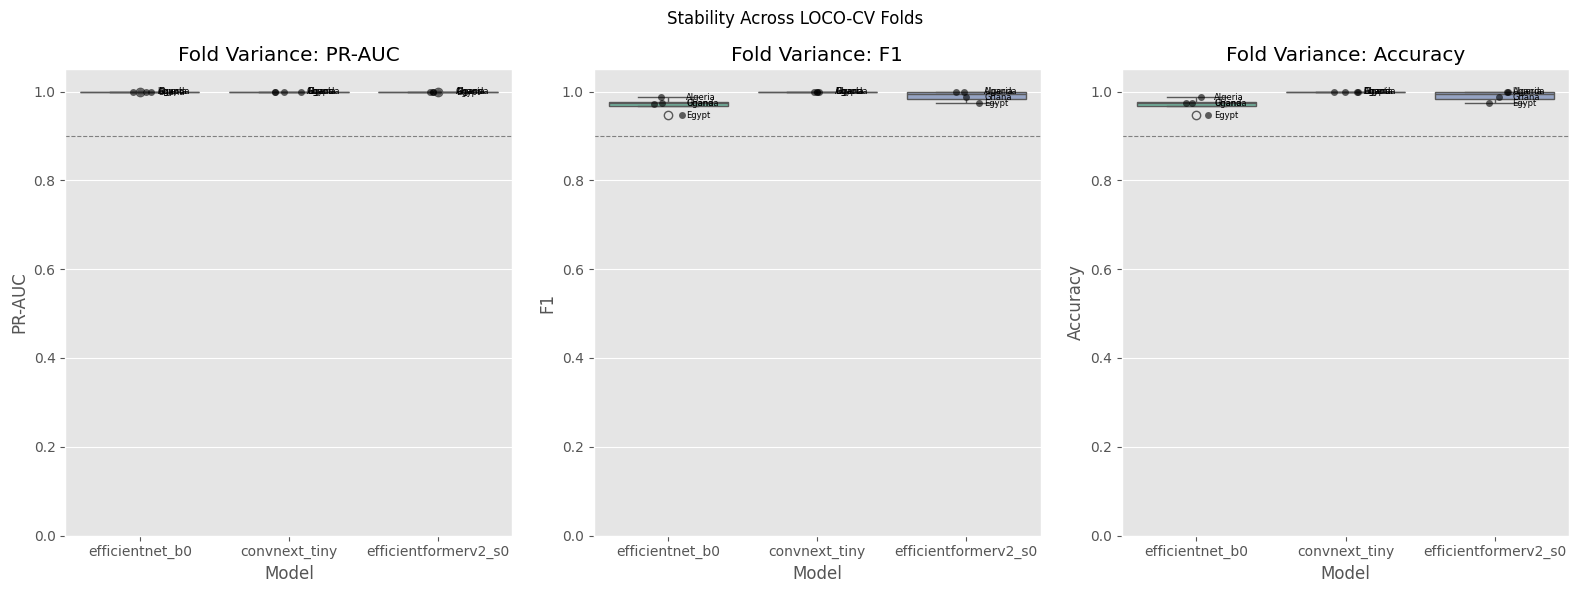

In [14]:
if results:
    # -- CV fold variance --------------------------------------------------
    cv_data = []
    for m_name, res in results.items():
        for fold_country, metrics in res["fold_results"].items():
            cv_data.append({
                "Model"      : m_name,
                "Val Country": fold_country,
                "PR-AUC"     : metrics.get("val_pr_auc", 0),
                "F1"         : metrics.get("val_f1",     0),
                "Accuracy"   : metrics.get("val_acc",    0),
            })

    df_cv = pd.DataFrame(cv_data)
    print("CV Fold Results:")
    print(df_cv.to_string(index=False))

    fig, axes = plt.subplots(1, 3, figsize=(16, 6))

    for ax, metric in zip(axes, ["PR-AUC", "F1", "Accuracy"]):
        sns.boxplot(data=df_cv,   x="Model", y=metric, ax=ax, palette="Set2")
        sns.stripplot(data=df_cv, x="Model", y=metric, ax=ax,
                      color="black", alpha=0.6, jitter=True,
                      dodge=False)
        # Annotate each dot with the country
        for _, row in df_cv.iterrows():
            models_list = df_cv["Model"].unique().tolist()
            x_pos = models_list.index(row["Model"])
            ax.text(x_pos + 0.12, row[metric], row["Val Country"],
                    fontsize=6, va="center")
        ax.set_title(f"Fold Variance: {metric}")
        ax.set_ylim(0, 1.05)
        ax.axhline(0.9, color="gray", ls="--", lw=0.8)

    plt.suptitle("Stability Across LOCO-CV Folds", fontsize=12)
    plt.tight_layout()
    plt.savefig("docs/loco_fold_variance.png", dpi=150)
    plt.show()


In [15]:
if results:
    # -- Mean +/- Std summary table -------------------------------------------
    summary_rows = []
    for m_name, res in results.items():
        mean = res["mean_cv_metrics"]
        std  = res["std_cv_metrics"]
        summary_rows.append({
            "Model"          : m_name,
            "CV PR-AUC"      : f"{mean.get('val_pr_auc',0):.3f} +/- {std.get('val_pr_auc',0):.3f}",
            "CV F1"          : f"{mean.get('val_f1',0):.3f} +/- {std.get('val_f1',0):.3f}",
            "CV Accuracy"    : f"{mean.get('val_acc',0):.3f} +/- {std.get('val_acc',0):.3f}",
            "Test PR-AUC"    : f"{res['mean_test_metrics'].get('pr_auc',0):.3f}",
            "Test F1"        : f"{res['mean_test_metrics'].get('f1',0):.3f}",
            "Test Accuracy"  : f"{res['mean_test_metrics'].get('accuracy',0):.3f}",
        })

    df_summary = pd.DataFrame(summary_rows).set_index("Model")
    print("\nFull Summary (CV mean +/- std | Malawi Test):")
    print(df_summary.to_string())
    df_summary.to_csv("docs/loco_cv_summary.csv")
    print("Saved to docs/loco_cv_summary.csv")



Full Summary (CV mean +/- std | Malawi Test):
                          CV PR-AUC          CV F1    CV Accuracy Test PR-AUC Test F1 Test Accuracy
Model                                                                                              
efficientnet_b0       1.000 +/- 0.001  0.970 +/- 0.015  0.970 +/- 0.015       0.999   0.970         0.970
convnext_tiny         1.000 +/- 0.000  1.000 +/- 0.000  1.000 +/- 0.000       0.994   0.979         0.980
efficientformerv2_s0  0.999 +/- 0.001  0.990 +/- 0.011  0.990 +/- 0.011       0.998   0.973         0.973
Saved to docs/loco_cv_summary.csv
